# 1.0 Sobre o Notebook

- O objetivo deste notebook é criar os gráficos referentes as análises do dataset Olist
- Fonte dos dados: https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce
- Os dados utilizados são gerados pelo notebook *03_analise.ipynb*, em data/results

# 2.0 Problema de Negócio

- A Olist apresenta crescimento nas vendas e satisfação de clientes que justifiquem investimentos na expansão da plataforma?
    - As vendas estão crescendo? -> Analisar a evolução mensal dos pedidos e valor vendido
    - Os clientes estão satisfeitos? -> Analisar review score
    - O que prejudica a satisfação de um cliente? -> Analisar prazo de entrega x review_score
    - Onde estão as oportunidades? -> Olhar categorias e regiões com melhor/pior desempenho

# 3.0 Imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 4.0 Carregamento dos Dados

In [2]:
atraso_x_avaliacao = pd.read_csv('../data/results/atraso_x_avaliacao.csv', index_col=0)
mensal_atraso_insatisfacao = pd.read_csv('../data/results/mensal_atraso_insatisfacao.csv', index_col=0)
metricas_mensais = pd.read_csv('../data/results/metricas_mensais.csv', index_col=0)
metricas_regiao = pd.read_csv('../data/results/metricas_regiao.csv', index_col=0)

## 4.1 Checagem das Tabelas

In [3]:
print(atraso_x_avaliacao.shape)
print(mensal_atraso_insatisfacao.shape)
print(metricas_mensais.shape)
print(metricas_regiao.shape)

(2, 3)
(20, 2)
(20, 3)
(5, 8)


# 5.0 Gráficos

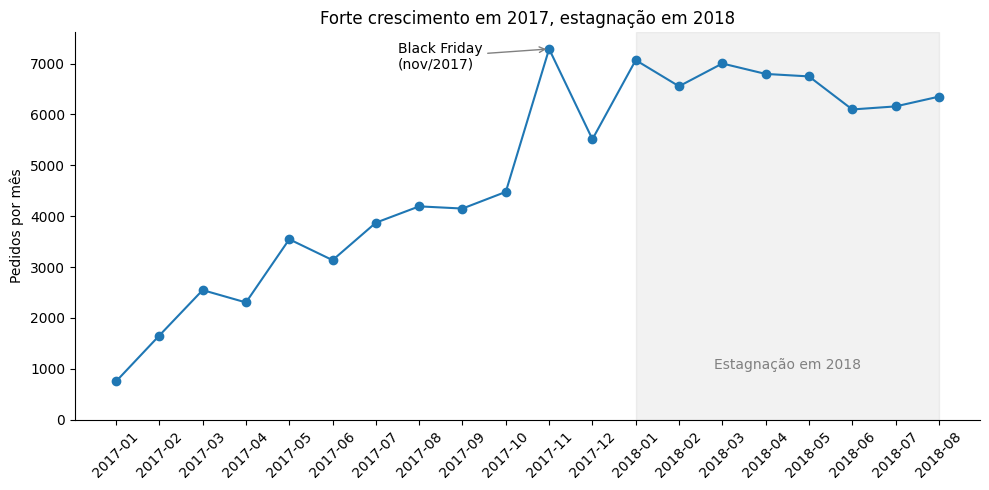

In [4]:
# G1 - pedidos por mês
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(metricas_mensais.index, metricas_mensais['qtd_pedidos'], marker='o')

ax.set_title('Forte crescimento em 2017, estagnação em 2018')
ax.set_ylabel('Pedidos por mês')
ax.set_ylim(0, None)
ax.tick_params(axis='x', rotation=45)

# faixa sombreada em 2018 (estagnação)
ax.axvspan(12, 19, color='gray', alpha=0.1)
ax.text(15.5, 1000, 'Estagnação em 2018', ha='center', color='gray')

# anotação do pico de nov/2017
pos_nov = list(metricas_mensais.index).index('2017-11')
ax.annotate('Black Friday\n(nov/2017)',
            xy=(pos_nov, metricas_mensais.loc['2017-11', 'qtd_pedidos']),
            xytext=(pos_nov - 3.5, 6900),
            arrowprops=dict(arrowstyle='->', color='gray'))

ax.spines[['top', 'right']].set_visible(False)

plt.tight_layout()

fig.savefig('../img/g1_pedidos_mes.png', dpi=200, bbox_inches='tight')

plt.show()

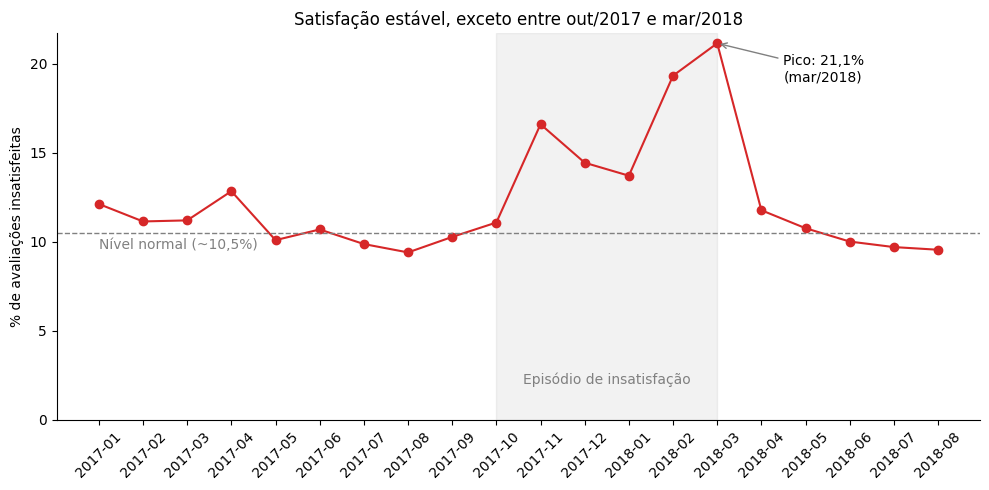

In [5]:
# G2 - % de insatisfeitos por mês
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(mensal_atraso_insatisfacao.index, mensal_atraso_insatisfacao['pct_insatisfeitos'],
        marker='o', color='tab:red')

ax.set_title('Satisfação estável, exceto entre out/2017 e mar/2018')
ax.set_ylabel('% de avaliações insatisfeitas')
ax.set_yticks(range(0, 25, 5))
ax.set_ylim(0, None)
ax.tick_params(axis='x', rotation=45)

# posições do episódio (calculadas a partir da tabela)
meses = list(mensal_atraso_insatisfacao.index)
pos_ini = meses.index('2017-10')
pos_fim = meses.index('2018-03')

# faixa sombreada no episódio
ax.axvspan(pos_ini, pos_fim, color='gray', alpha=0.1)
ax.text((pos_ini + pos_fim) / 2, 2, 'Episódio de insatisfação', ha='center', color='gray')

# linha do nível normal (antes: 10,51% | depois: 10,38% - calculados no 03_analise)
nivel_normal = 10.5
ax.axhline(nivel_normal, color='gray', linestyle='--', linewidth=1)
ax.text(0, nivel_normal - 0.9, 'Nível normal (~10,5%)', color='gray')

# anotação do pico de mar/2018
ax.annotate('Pico: 21,1%\n(mar/2018)',
            xy=(pos_fim, mensal_atraso_insatisfacao.loc['2018-03', 'pct_insatisfeitos']),
            xytext=(pos_fim + 1.5, 19),
            arrowprops=dict(arrowstyle='->', color='gray'))

ax.spines[['top', 'right']].set_visible(False)

plt.tight_layout()

fig.savefig('../img/g2_insatisfacao_mes.png', dpi=200, bbox_inches='tight')

plt.show()


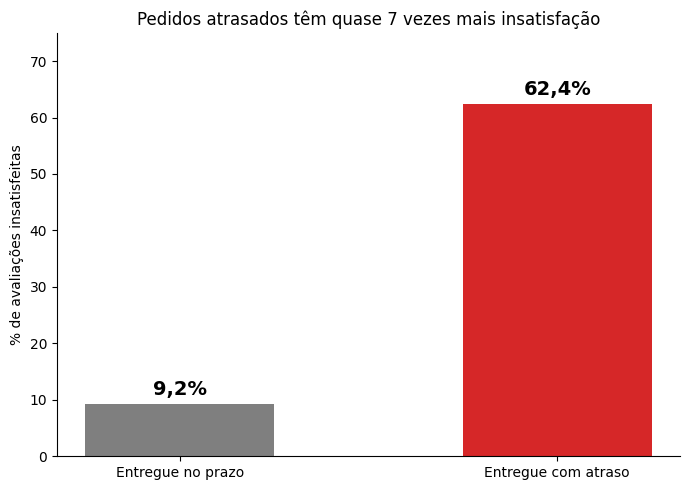

In [6]:
# G3 - % de insatisfeitos por tipo de entrega
dados_g3 = atraso_x_avaliacao.loc[['no prazo', 'atrasado'], 'insatisfeito']

fig, ax = plt.subplots(figsize=(7, 5))

barras = ax.bar(['Entregue no prazo', 'Entregue com atraso'], dados_g3,
                color=['tab:gray', 'tab:red'], width=0.5)

# valor em cima de cada barra
ax.bar_label(barras, labels=[f'{v:.1f}%'.replace('.', ',') for v in dados_g3],
             fontsize=14, fontweight='bold', padding=4)

ax.set_title('Pedidos atrasados têm quase 7 vezes mais insatisfação')
ax.set_ylabel('% de avaliações insatisfeitas')
ax.set_ylim(0, 75)

ax.spines[['top', 'right']].set_visible(False)

plt.tight_layout()

fig.savefig('../img/g3_insatisfacao_atraso.png', dpi=200, bbox_inches='tight')

plt.show()

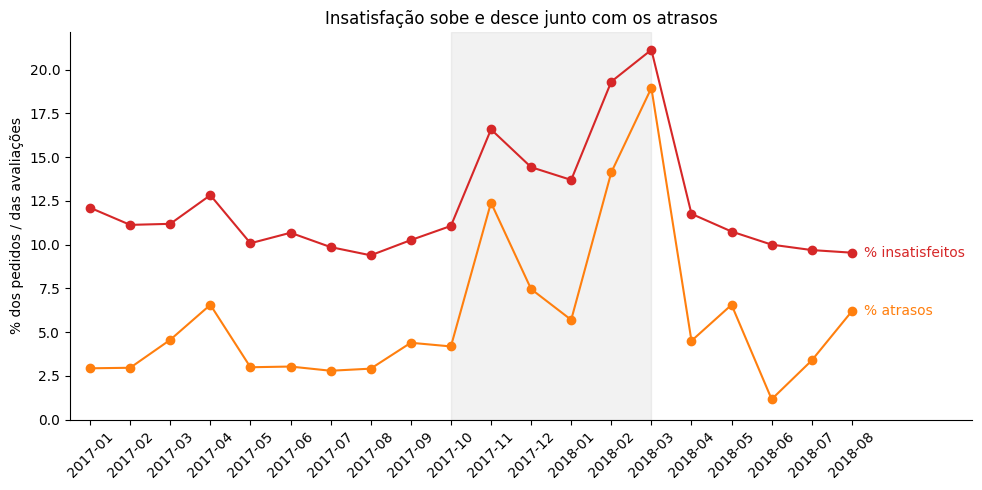

In [7]:
# G4 - % de atrasos e % de insatisfeitos por mês
fig, ax = plt.subplots(figsize=(10, 5))

meses = list(mensal_atraso_insatisfacao.index)

ax.plot(meses, mensal_atraso_insatisfacao['pct_insatisfeitos'], marker='o', color='tab:red')
ax.plot(meses, mensal_atraso_insatisfacao['pct_atrasos'], marker='o', color='tab:orange')

# rótulos no fim das linhas (substituem a legenda)
ultimo = len(meses) - 1
ax.text(ultimo + 0.3, mensal_atraso_insatisfacao['pct_insatisfeitos'].iloc[-1],
        '% insatisfeitos', color='tab:red', va='center')
ax.text(ultimo + 0.3, mensal_atraso_insatisfacao['pct_atrasos'].iloc[-1],
        '% atrasos', color='tab:orange', va='center')

# faixa sombreada no episódio
pos_ini = meses.index('2017-10')
pos_fim = meses.index('2018-03')
ax.axvspan(pos_ini, pos_fim, color='gray', alpha=0.1)

ax.set_title('Insatisfação sobe e desce junto com os atrasos')
ax.set_ylabel('% dos pedidos / das avaliações')
ax.set_ylim(0, None)
ax.set_xlim(-0.5, ultimo + 3)
ax.tick_params(axis='x', rotation=45)

ax.spines[['top', 'right']].set_visible(False)

plt.tight_layout()

fig.savefig('../img/g4_atraso_insatisfacao_mes.png', dpi=200, bbox_inches='tight')

plt.show()

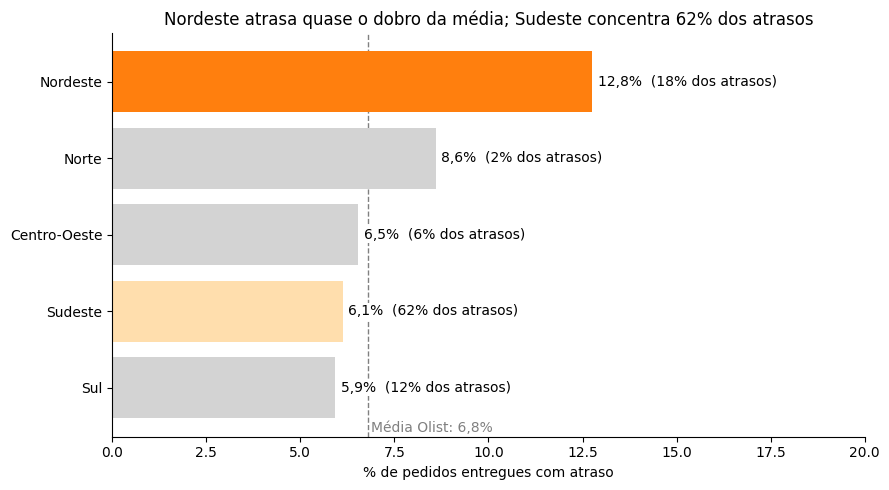

In [8]:
# G5 - taxa de atraso por região, com a média da Olist
dados_g5 = metricas_regiao.sort_values('pct_atrasos')

# média da Olist calculada a partir da própria tabela (total de atrasos / total de pedidos)
media_olist = metricas_regiao['atrasos'].sum() / metricas_regiao['pedidos'].sum() * 100

cores_regiao = {'Nordeste': 'tab:orange', 'Sudeste': 'navajowhite'}
cores = [cores_regiao.get(r, 'lightgray') for r in dados_g5.index]

fig, ax = plt.subplots(figsize=(9, 5))

barras = ax.barh(dados_g5.index, dados_g5['pct_atrasos'], color=cores)

# rótulo: taxa de atraso e participação no total de atrasos da Olist
rotulos = [f"{taxa:.1f}%  ({part:.0f}% dos atrasos)".replace('.', ',')
           for taxa, part in zip(dados_g5['pct_atrasos'], dados_g5['pct_do_total_atrasos'])]
ax.bar_label(barras, labels=rotulos, padding=4,
             bbox=dict(facecolor='white', edgecolor='none', pad=1))

# linha da média da Olist
ax.axvline(media_olist, color='gray', linestyle='--', linewidth=1, zorder=0)
ax.text(media_olist + 0.1, -0.58, f'Média Olist: {media_olist:.1f}%'.replace('.', ','), color='gray')

ax.set_title('Nordeste atrasa quase o dobro da média; Sudeste concentra 62% dos atrasos')
ax.set_xlabel('% de pedidos entregues com atraso')
ax.set_xlim(0, 20)

ax.spines[['top', 'right']].set_visible(False)

plt.tight_layout()

fig.savefig('../img/g5_atraso_regiao.png', dpi=200, bbox_inches='tight')

plt.show()

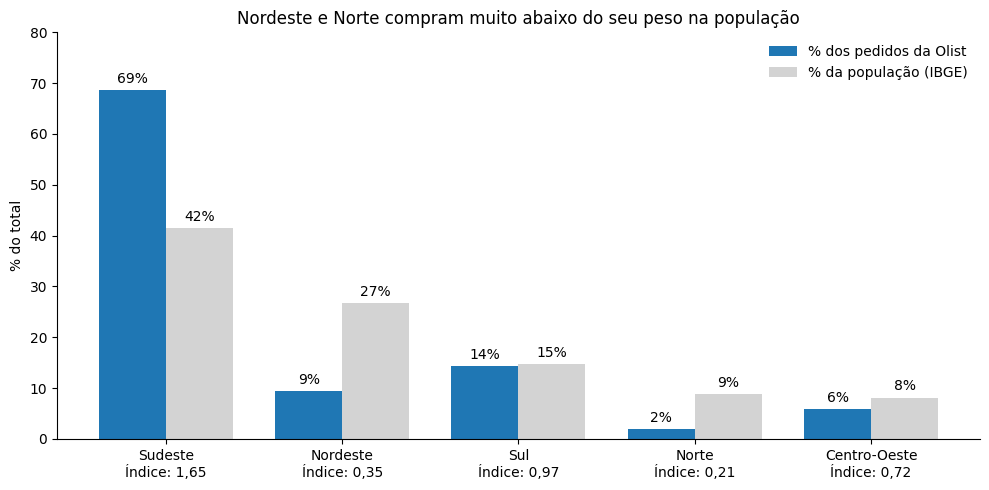

In [9]:
# G6 - % dos pedidos x % da população por região
dados_g6 = metricas_regiao.sort_values('pct_populacao', ascending=False)

x = np.arange(len(dados_g6))   # posição de cada região no eixo: 0, 1, 2, 3, 4
largura = 0.38

fig, ax = plt.subplots(figsize=(10, 5))

barras_pedidos = ax.bar(x - largura/2, dados_g6['pct_pedidos'], largura,
                        color='tab:blue', label='% dos pedidos da Olist')
barras_pop = ax.bar(x + largura/2, dados_g6['pct_populacao'], largura,
                    color='lightgray', label='% da população (IBGE)')

# valores em cima das barras
fmt = lambda serie: [f'{v:.0f}%' for v in serie]
ax.bar_label(barras_pedidos, labels=fmt(dados_g6['pct_pedidos']), padding=3)
ax.bar_label(barras_pop, labels=fmt(dados_g6['pct_populacao']), padding=3)

# nome da região com o índice de penetração embaixo
rotulos_x = [f'{r}\nÍndice: {i:.2f}'.replace('.', ',')
             for r, i in zip(dados_g6.index, dados_g6['indice_penetracao'])]
ax.set_xticks(x)
ax.set_xticklabels(rotulos_x)

ax.set_title('Nordeste e Norte compram muito abaixo do seu peso na população')
ax.set_ylabel('% do total')
ax.set_ylim(0, 80)
ax.legend(frameon=False)

ax.spines[['top', 'right']].set_visible(False)

plt.tight_layout()

fig.savefig('../img/g6_penetracao_regiao.png', dpi=200, bbox_inches='tight')

plt.show()